# Atmospheric transmittance of the water-leaving signal

How much of the light leaving the water reaches a satellite sensor, and how much of the sunlight reaches
the sea surface? Atmospheric correction algorithms usually answer with the analytical *diffuse
transmittance* approximation

$$
t(\mu) = \exp\left[-\frac{a\,\tau_r + b\,\tau_a}{\mu}\right],
$$

with $\tau_r$ and $\tau_a$ the Rayleigh and aerosol optical thicknesses, $\mu$ the cosine of the zenith
angle, $a \simeq 0.5$ (half of the Rayleigh scattering is forward) and $b = 1 - \omega_a F_a$ (aerosol
absorption plus the backward-scattered part of the aerosol scattering, $\omega_a$ single scattering
albedo, $F_a$ forward-scattering fraction).

This notebook checks this approximation against vector radiative transfer simulations (OSOAA) of the
coupled atmosphere-ocean system, for the downward irradiance and for the upward water-leaving
radiance, including its polarized part. The functions used here are defined in
[`case_study/transmittance/stokes_modeling.py`](https://github.com/Tristanovsk/RTxploitation/tree/master/case_study/transmittance/stokes_modeling.py),
which also regenerates all the figures as a script.

```{note}
The notebook is rendered with the outputs of its last run. The simulation files are not distributed
with RTxploitation: set `SCATMAT_DIR` and `OPAC_LUT` in the settings cell (or the `RTX_SCATMAT_DIR` and
`RTX_OPAC_LUT` environment variables) to run it on your own data. The notebook is in
[`case_study/transmittance/notebook/`](https://github.com/Tristanovsk/RTxploitation/tree/master/case_study/transmittance/notebook).
```

## Simulations

The [OSOAA](https://github.com/CNES/RadiativeTransferCode-OSOAA) runs (one file per wavelength,
400 to 850 nm every 25 nm) share:

- **atmosphere**: Rayleigh scattering and one lognormal aerosol mode ($r_g$ = 0.10 µm,
  $\sigma$ = 0.46, $m$ = 1.45 - 0.001i), AOT(550) = 0.1; wind speed of 2 m/s;
- **water**: 1 g/m³ of mineral particles (lognormal size distribution of median radius 1 µm, relative
  refractive index 1.15).

Each wavelength is run twice, with the ocean (`osoaa_tot_*`) and without it (`osoaa_nosea_*`). Their
difference isolates the **water-leaving** contribution to the Stokes vector $(I, Q, U)$ at every level,
which is what a transmittance of the water signal must be computed on. Three levels are kept:
$z=-10^{-6}$ (just below the surface, $0^-$), $z = 0$ (just above, $0^+$) and the top of atmosphere
(TOA, $z$ = 300 km). Radiances are normalized as reflectances, $\mathrm{Stokes}/(\pi\mu_0)$.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

# make RTxploitation and the case-study module importable from the notebook folder
root = os.path.abspath(os.path.join('..', '..', '..'))
sys.path[:0] = [root, os.path.join(root, 'case_study', 'transmittance')]

import stokes_modeling as sm

sm.set_style()
%matplotlib inline

In [2]:
# ---- settings ----
sm.SCATMAT_DIR = '/data/vrtc/lut/scat_mat/'
OPAC_LUT = sm.OPAC_LUT
print(sm.PREFIX)

osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2


### Load the Stokes parameters and fluxes

`load_simulations` wraps {func}`RTxploitation.load_lut_nc.load_osoaa` with `water_signal=True`.
`load_optical_thickness` reads the optical properties OSOAA actually used: the Rayleigh optical
thickness (`AP.MOT` attribute) and the aerosol optical thickness, single scattering albedo and
asymmetry parameter (`optical_properties/aerosol` group).

In [3]:
labels = sm.simulation_labels(spm='1.00', nr='1.15', rmed='1.0', wls=np.arange(400, 851, 25))
x = sm.load_simulations(labels, idir=sm.SCATMAT_DIR)
tau = sm.load_optical_thickness(labels, idir=sm.SCATMAT_DIR)
x

/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.400.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.425.nc
/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.450.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.475.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.500.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.525.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.550.nc
/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.575.nc


... (4 outputs left out)

/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.775.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.800.nc


/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.825.nc
/data/vrtc/lut/scat_mat/osoaa_tot_aot0.1_aero_rg0.10_sig0.46_nr1.45_ni-0.0010_ws2__sed1.00_nr1.15_rmed1.0_wl0.850.nc


<xarray.Dataset> Size: 27MB
Dimensions:     (wavelength: 19, z: 3, sza: 9, vza: 61, azi: 73)
Coordinates:
  * wavelength  (wavelength) float64 152B 400.0 425.0 450.0 ... 825.0 850.0
  * z           (z) float32 12B -1e-06 0.0 3e+05
  * sza         (sza) float32 36B 0.0 10.0 20.0 30.0 40.0 50.0 60.0 70.0 80.0
  * vza         (vza) float32 244B 0.0 1.14 2.62 4.11 ... 86.27 87.76 89.25
  * azi         (azi) float32 292B 0.0 5.0 10.0 15.0 ... 345.0 350.0 355.0 360.0
Data variables:
    Ed          (wavelength, z, sza) float32 2kB 0.8942 0.8787 ... 0.342 0.1736
    Eu          (wavelength, z, sza) float32 2kB 0.3129 0.3108 ... 0.05557
    Eo          (wavelength, z, sza) float32 2kB 1.382 1.366 ... 1.246 1.281
    Eddir       (wavelength, z, sza) float32 2kB 0.5814 0.568 ... 0.342 0.1736
    Eudir       (wavelength, z, sza) float32 2kB 0.0 0.0 0.0 ... 0.03017 0.0238
    Eodir       (wavelength, z, sza) float32 2kB 0.5816 0.573 ... 1.113 1.135
    I           (wavelength, z, sza, vza, azi) float32 9MB nan nan ... 1.464e-05
    Q           (wavelength, z, sza, vza, azi) float32 9MB nan nan ... 3.688e-07
    U           (wavelength, z, sza, vza, azi) float32 9MB nan ... -5.489e-22

In [4]:
tau.to_dataframe().round(4).iloc[::2]

,rot,aot,ssa,asym_factor
wavelength,,,,
400.0,0.3603,0.1596,0.9942,0.7160
450.0,0.2211,0.1370,0.9942,0.7022
500.0,0.1434,0.1171,0.9941,0.6868
550.0,0.0971,0.1000,0.9939,0.6703
600.0,0.0681,0.0855,0.9936,0.6530
650.0,0.0492,0.0732,0.9933,0.6351
700.0,0.0364,0.0629,0.9930,0.6169
750.0,0.0276,0.0542,0.9926,0.5986
800.0,0.0212,0.0468,0.9922,0.5801


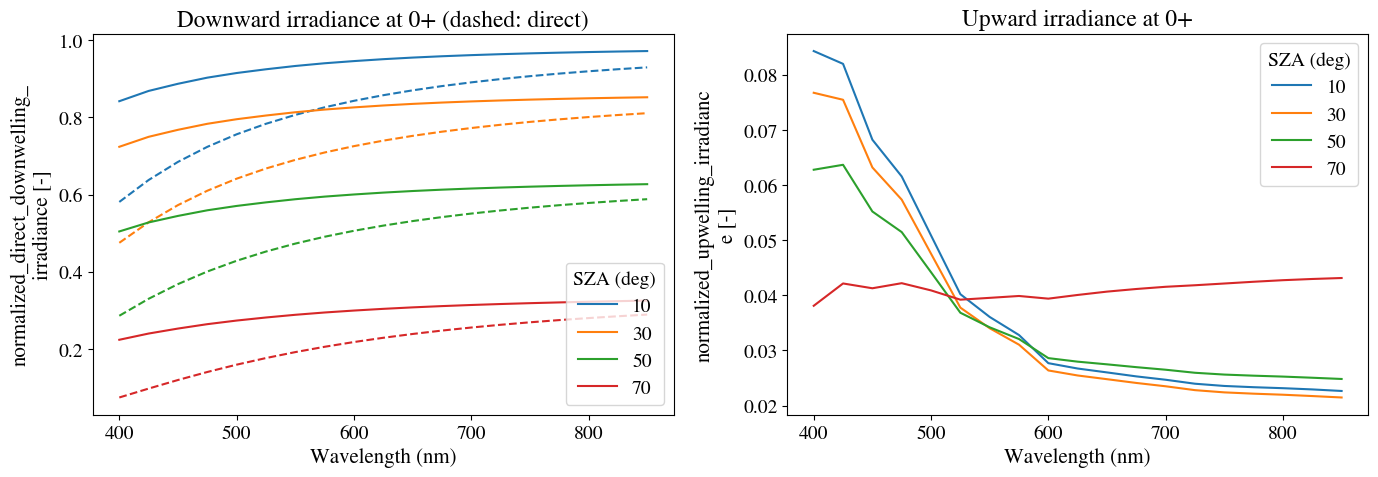

In [5]:
fig = sm.plot_irradiance(x)

## Downward irradiance

At TOA the downward irradiance is purely direct, $E_d(\mathrm{TOA}) = \mu_0 F_0$. The total
transmittance of the downward irradiance and its direct and diffuse parts are then

$$
T_{tot} = \frac{E_d(0^+)}{E_d(\mathrm{TOA})},\qquad
T_{dir} = \frac{E_d^{dir}(0^+)}{E_d(\mathrm{TOA})} = e^{-(\tau_r+\tau_a)/\mu_0},\qquad
T_{dif} = T_{tot} - T_{dir}.
$$

```{note}
The previous version of the script divided the diffuse irradiance at $0^+$ by the diffuse irradiance
at TOA, which is zero: the diffuse part is now normalized by the total TOA irradiance.
```

In [6]:
Td = sm.downward_transmittance(x)

# the direct transmittance is Beer-Lambert's law: a check of the optical thicknesses read above
for sza in [0, 30, 70]:
    err = np.abs(Td.T_dir.sel(sza=sza) - np.exp(-(tau.rot + tau.aot) / sm.mu(sza))).max()
    print('SZA=%2d  max |T_dir - exp(-tau/mu0)| = %.1e' % (sza, err))

SZA= 0  max |T_dir - exp(-tau/mu0)| = 3.2e-06
SZA=30  max |T_dir - exp(-tau/mu0)| = 3.6e-06
SZA=70  max |T_dir - exp(-tau/mu0)| = 7.5e-06


In the figure, the dotted lines of the left panel are the approximation with $a = 0.5$ and
$b = 1-\omega_a(1+g)/2$ ($g$ asymmetry parameter, as a proxy of $F_a$); in the middle panel they are
Beer-Lambert's law, which overlays the OSOAA curves exactly.

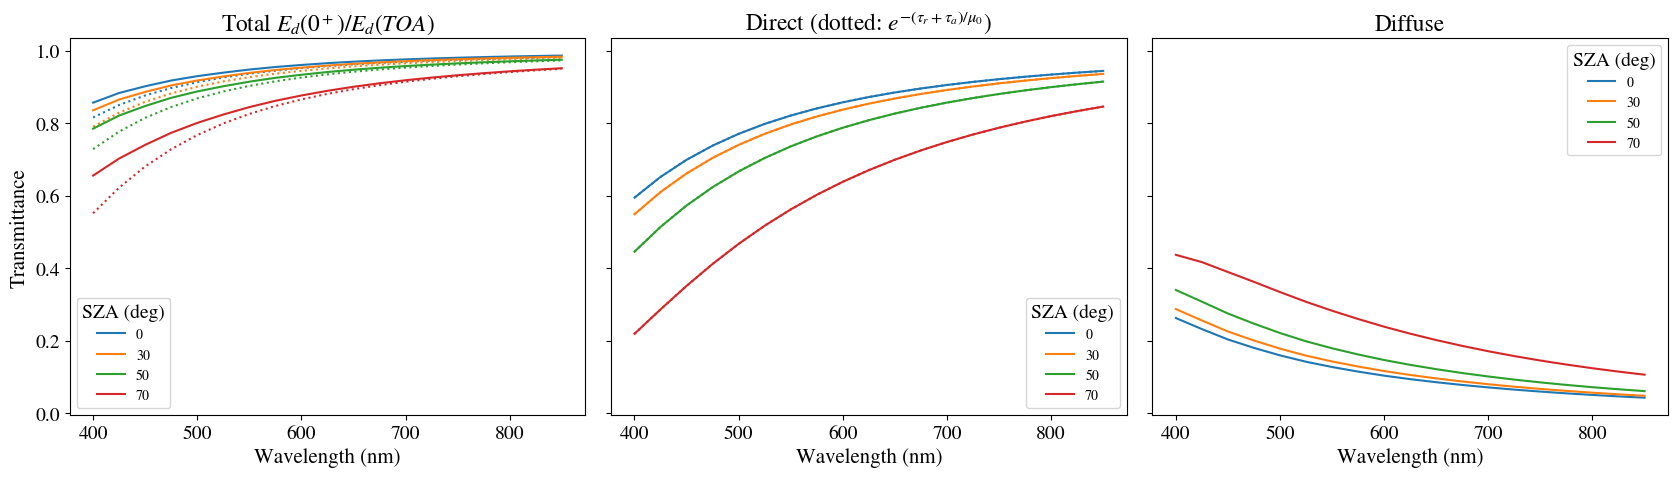

In [7]:
fig = sm.plot_downward_transmittance(Td, tau)

The simulated total transmittance is higher than the approximation, especially in the blue and at
large solar zenith angles: the approximation ignores the light reflected by the bright (sediment-loaded)
water and the surface, then backscattered down by the atmosphere. Fitting $(a, b)$ on the spectra for
each SZA gives effective coefficients well below $a = 0.5$ for Rayleigh:

In [8]:
T_ = Td.T_tot.sel(sza=slice(0, 70))
fit_down = sm.fit_coefficients(T_, tau.rot, tau.aot, sm.mu(T_.sza))
fit_down.to_dataframe().round(4)

,a,b,rms
sza,,,
0.0,0.3446,0.1925,0.0005
10.0,0.3439,0.1947,0.0005
20.0,0.3415,0.2019,0.0005
30.0,0.3368,0.2151,0.0004
40.0,0.3287,0.2358,0.0004
50.0,0.3150,0.2647,0.0003
60.0,0.2938,0.2972,0.0003
70.0,0.2638,0.3179,0.0006


## Upward water-leaving radiance

The Stokes parameters of the water-leaving signal at $0^+$ and at TOA give the transmittances

$$
t_I = \frac{I(\mathrm{TOA})}{I(0^+)}, \qquad
t_P = \frac{L_p(\mathrm{TOA})}{L_p(0^+)}, \quad L_p = \sqrt{Q^2+U^2},
$$

and the degree of linear polarization $\mathrm{DoLP} = L_p / I$ at both levels. Ratios of $Q$ and $U$
themselves are avoided: they are ill-defined where $Q$ or $U$ crosses zero ($U$ vanishes in the
principal plane).

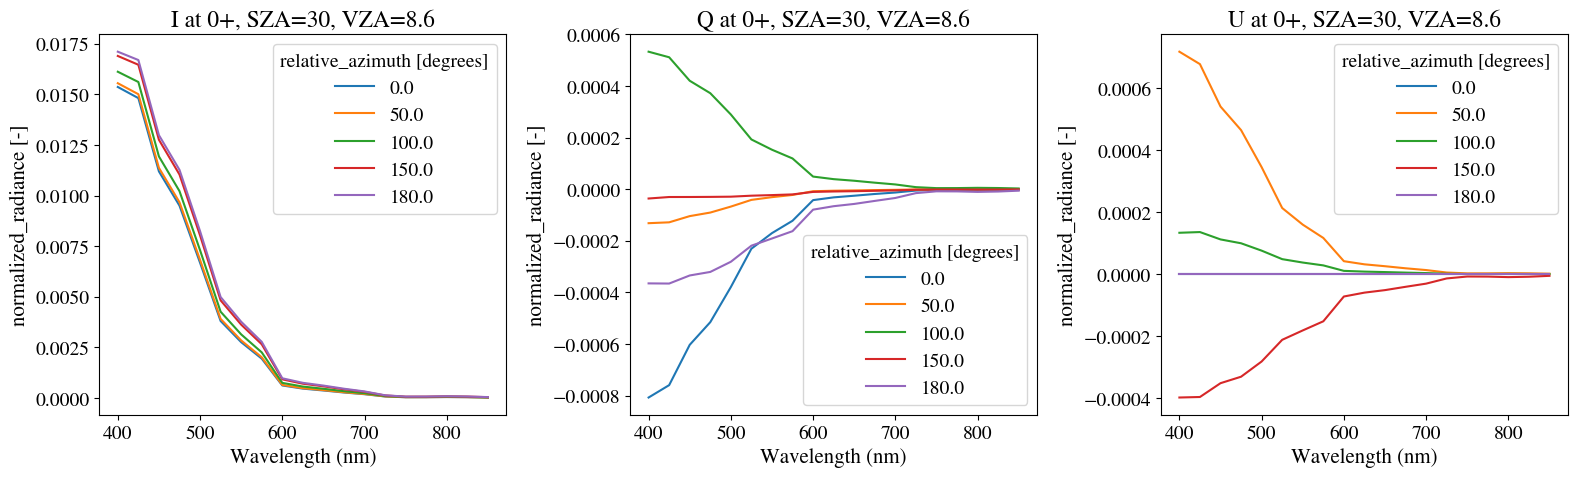

In [9]:
fig = sm.plot_stokes_spectra(x, sza=30, vza_idx=6)

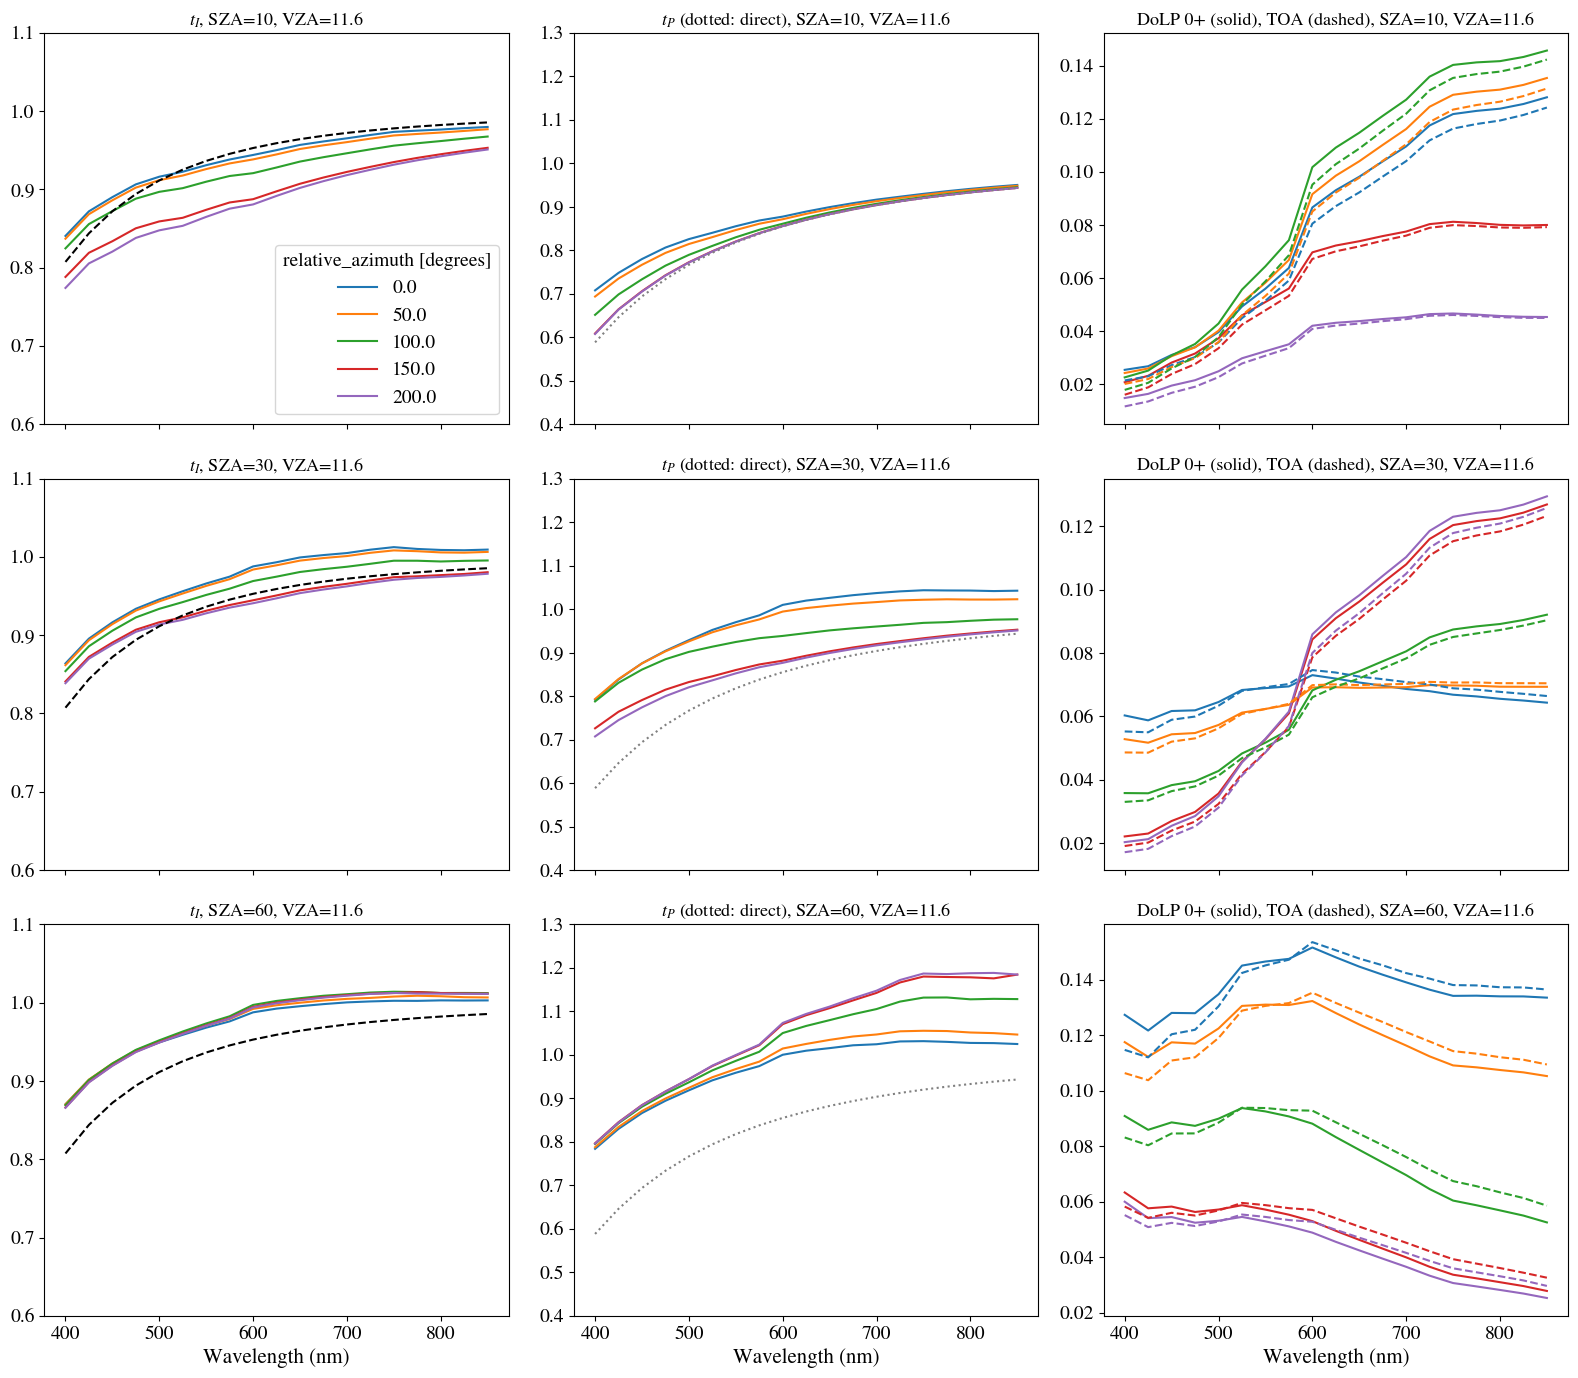

In [10]:
tu = sm.upward_transmittance(x)
fig = sm.plot_upward_transmittance_polar(tu, tau, szas=(10, 30, 60), vza_idx=8)

- $t_I$ (left, dashed: $a=0.52$, $b=0.14$) depends on the relative azimuth: the atmosphere scatters
  into the viewing direction water-leaving light that left the water in other directions, so the
  "transmittance" also carries the angular shape of the water-leaving radiance. It can exceed 1.
- $t_P$ (middle) is larger than the direct transmittance (dotted): the polarized part of the signal
  is also refilled by scattering, and at large SZA even exceeds 1.
- The DoLP of the water signal is only slightly changed by the atmosphere (right).

The same comparison for three viewing and three solar zenith angles:

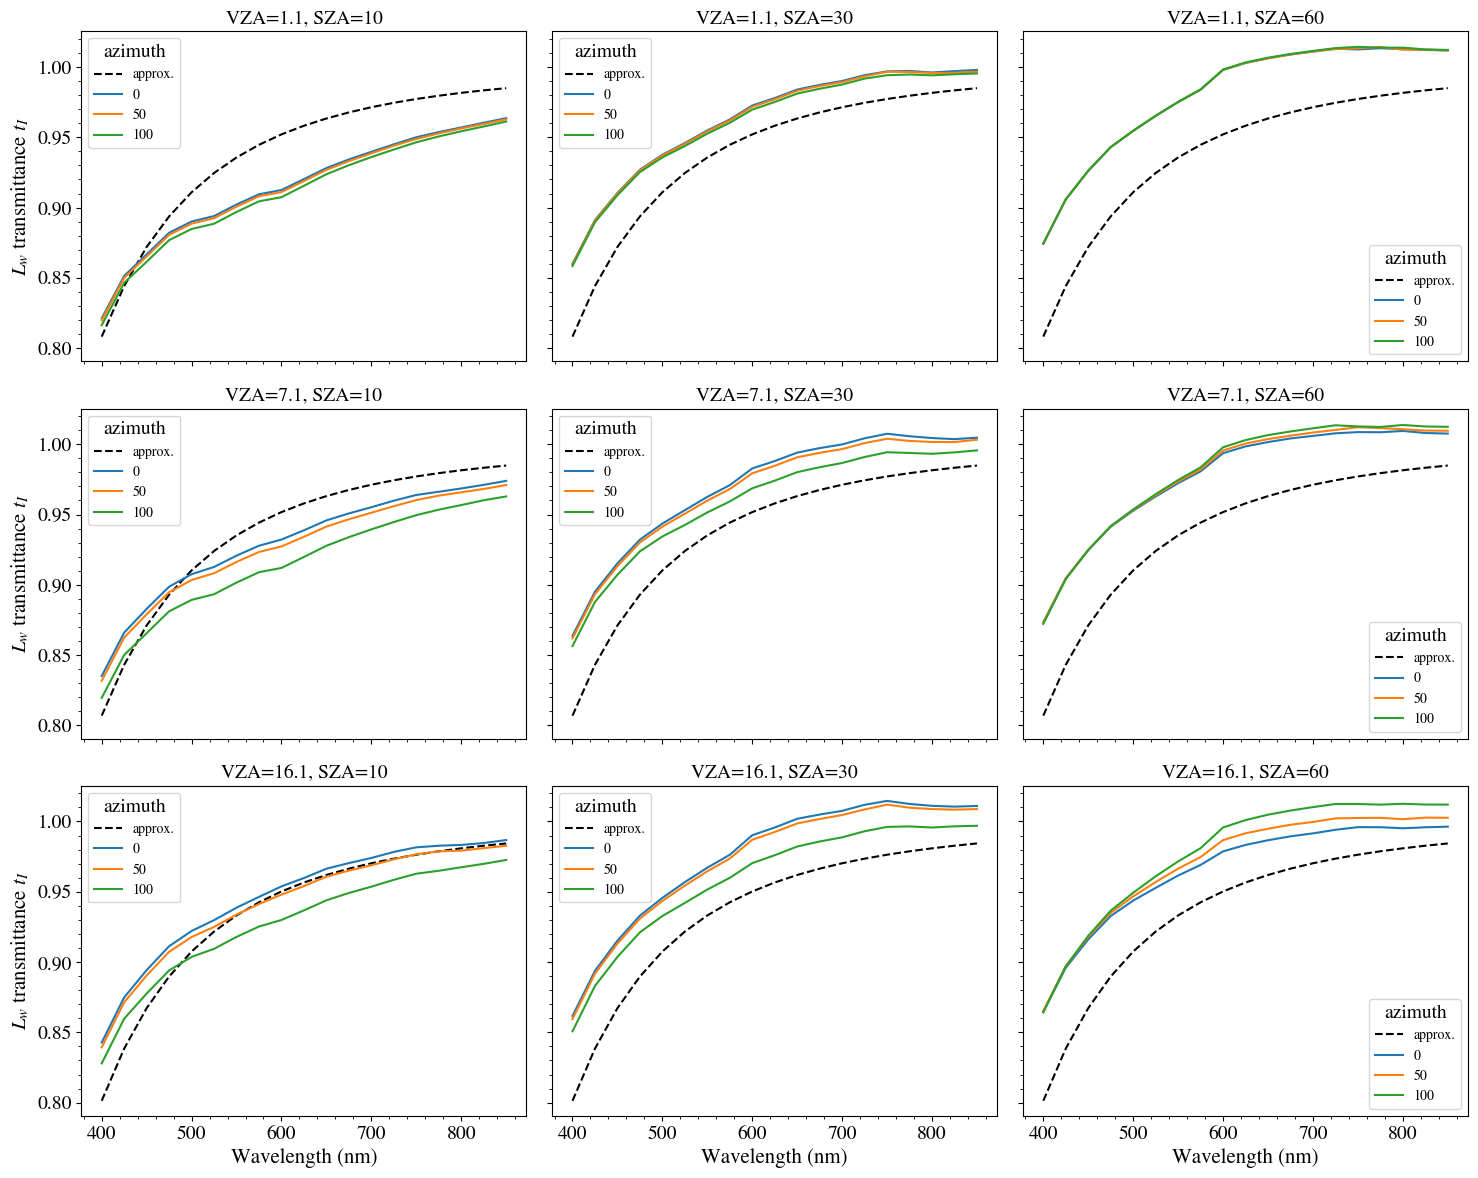

In [11]:
fig = sm.plot_transmittance_grid(
    tu.t_I, tau, lambda m0, mv: sm.transmittance_approx(tau.rot, tau.aot, mv, 0.52, 0.16),
    '$L_w$ transmittance $t_I$')

### Error of the classical approximation

Averaged over azimuth, the relative error of $\exp[-(0.52\,\tau_r + 0.16\,\tau_a)/\mu_v]$ stays within
a few percent from 550 nm onwards, but reaches 5-10 % at 400 nm where Rayleigh scattering dominates,
and diverges at large viewing angles. A per-geometry spectral fit of $(a, b)$ on $t_I$ is not robust
(it gives unphysical negative $b$): the azimuthal and angular effects are not captured by a single
exponential law.

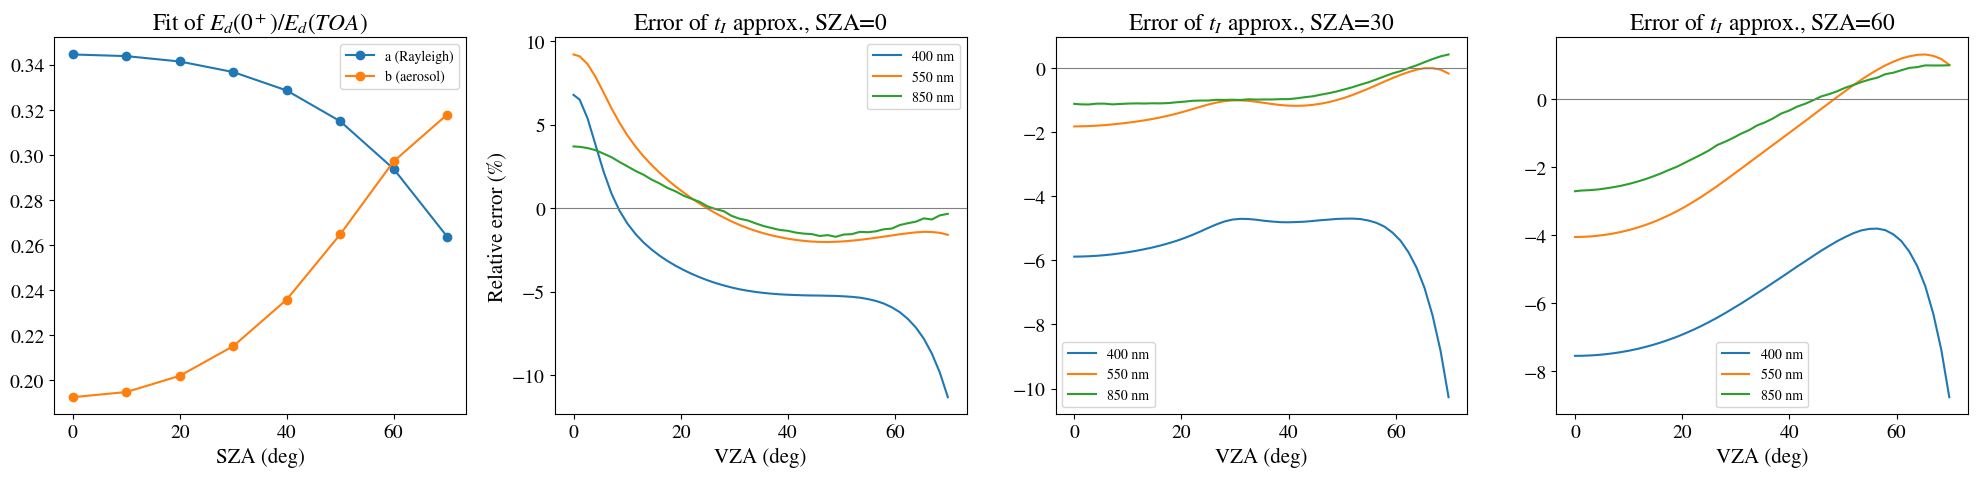

In [12]:
err_up = sm.upward_approx_error(tu, tau, a=0.52, b=0.16)
fig = sm.plot_fitted_coefficients(fit_down, err_up)

## Combined transmittance

The sun → surface → sensor transmittance of the water signal is $T_{tot}(\mu_0)\,t_I(\mu_v)$, compared
here with $\exp[-(0.5\,\tau_r + 0.12\,\tau_a)(1/\mu_0 + 1/\mu_v)]$ (dashed).

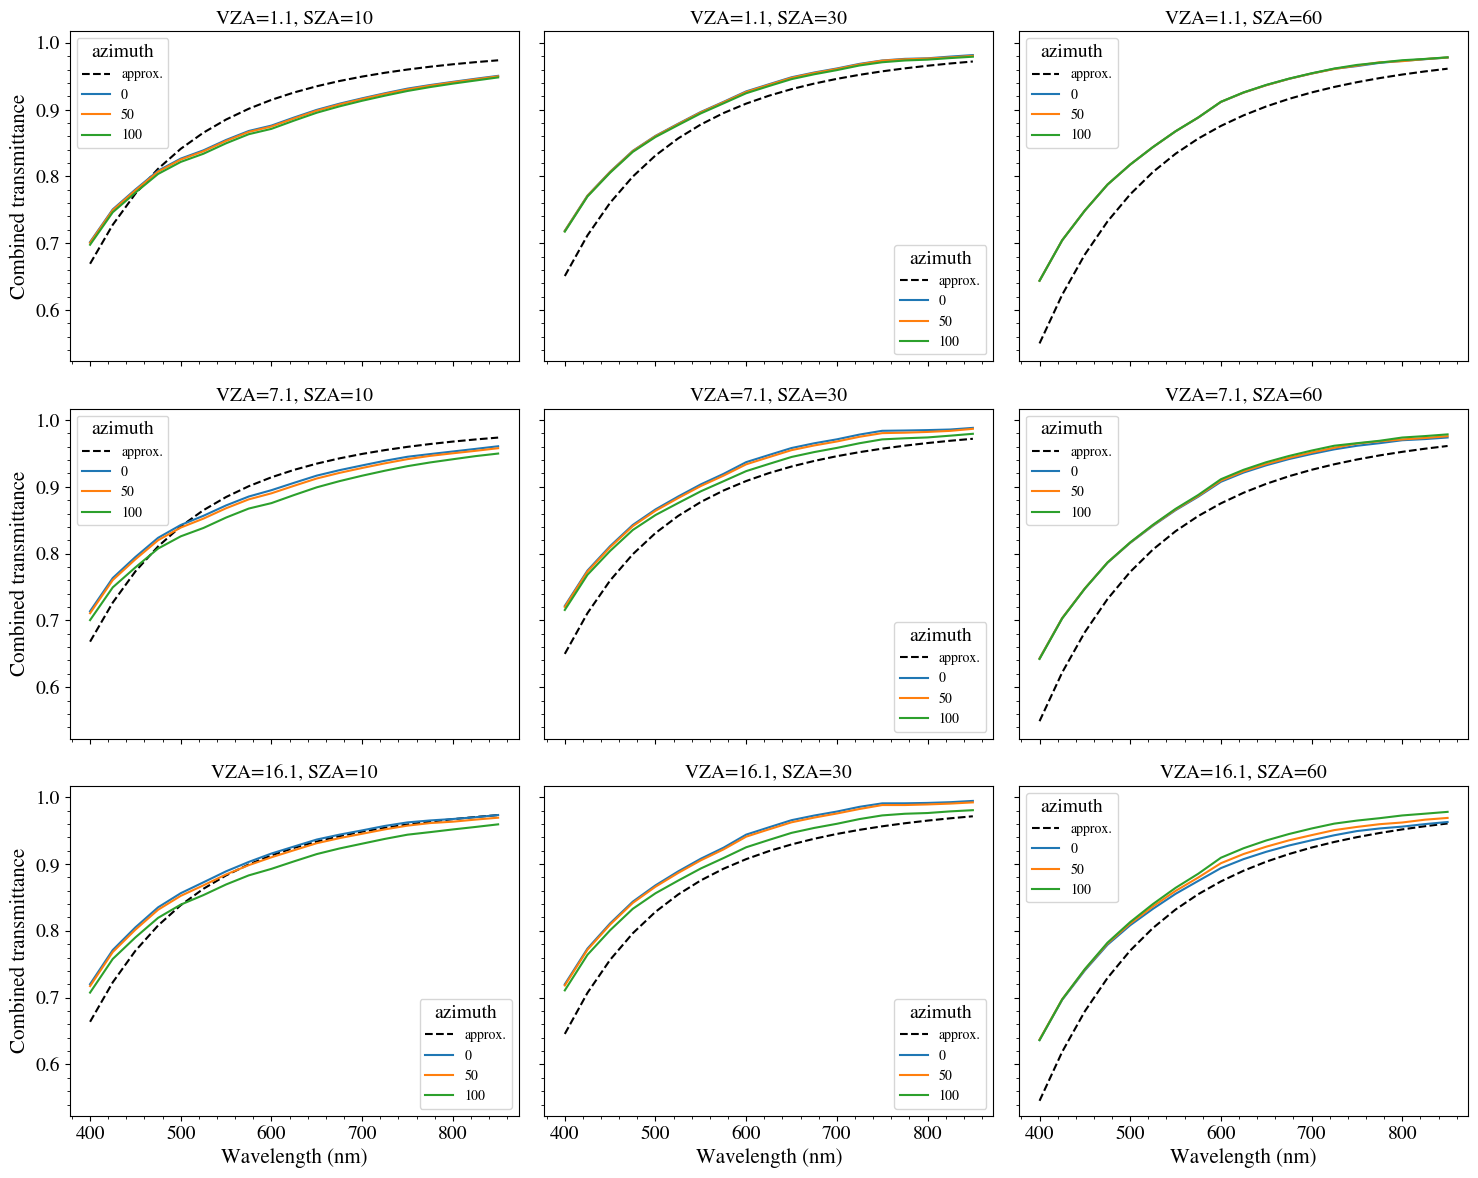

In [13]:
fig = sm.plot_transmittance_grid(
    tu.t_I * Td.T_tot, tau,
    lambda m0, mv: np.exp(-(0.5 * tau.rot + 0.12 * tau.aot) * (1 / m0 + 1 / mv)),
    'Combined transmittance')

## OPAC aerosol models

The GRS look-up table (`opac_osoaa_lut_v3.nc`) gives the irradiances for the OPAC aerosol models
(here at 70 % relative humidity) and AOT(550) from 0.001 to 1.5, from 350 to 2500 nm. The total downward
transmittance at SZA = 30° (solid) is compared with the absorption-only approximation (dotted)

$$
T_{tot} \simeq \exp\left[-\frac{0.52\,\tau_r + (1-\omega_a)\,\tau_a}{\mu_0}\right],
$$

which assumes that all the light scattered by aerosols reaches the surface. The Rayleigh optical
thickness is from Bodhaine et al. (1999), available up to 2450 nm.

```{note}
The previous version of the script used $\mu_0$ instead of the air mass $1/\mu_0$ in this
approximation.
```

The approximation holds for weakly absorbing, small particles at low AOT but fails for dust (DESE) and
for large AOT, where the light backscattered by aerosols is no longer negligible.

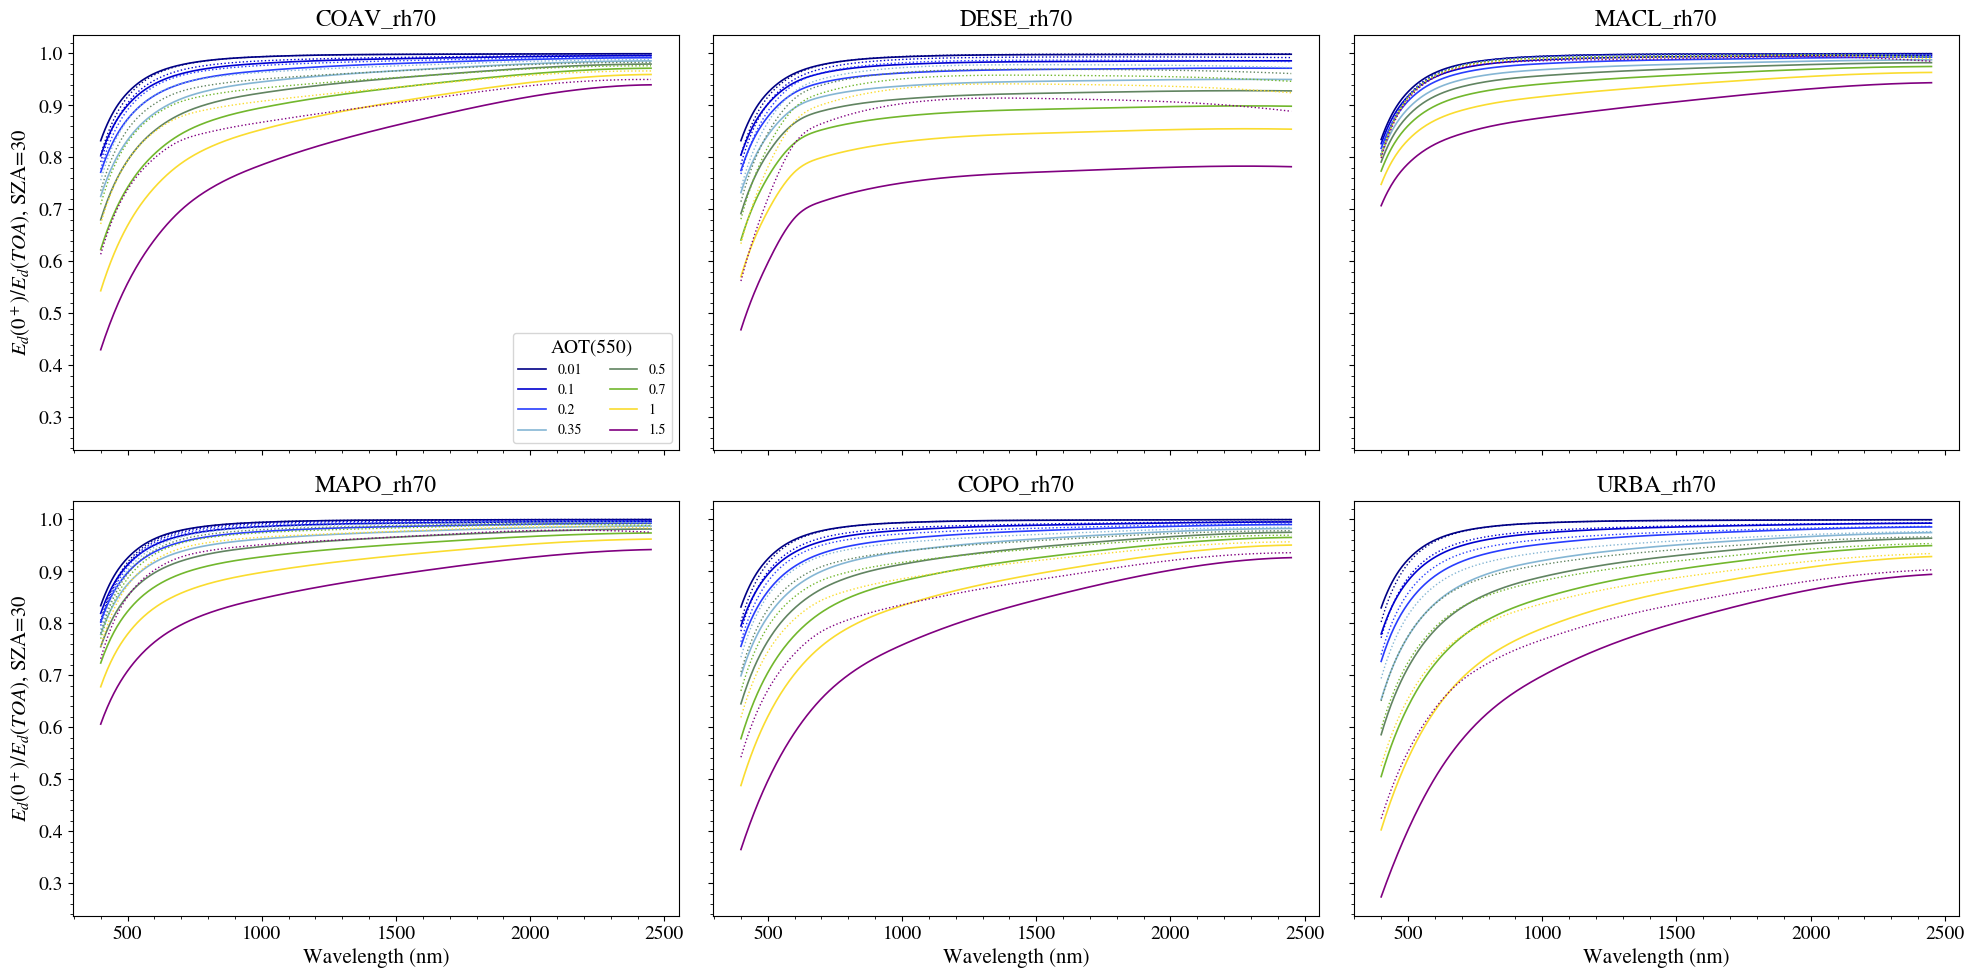

In [14]:
if os.path.exists(OPAC_LUT):
    fig = sm.plot_opac_downward(OPAC_LUT, sza=30)
else:
    print('OPAC LUT not found:', OPAC_LUT)

## Summary

- The direct transmittance of the OSOAA simulations follows Beer-Lambert's law to a few $10^{-6}$.
- The total downward transmittance over a bright water body is underestimated by the classical
  approximation; effective coefficients are $a \approx 0.26$–$0.34$ and $b \approx 0.19$–$0.32$
  depending on the SZA.
- The diffuse transmittance of the water-leaving radiance depends on the relative azimuth and the
  water angular distribution; the approximation $a = 0.52$, $b = 0.16$ is accurate to a few percent
  above 500 nm but not in the blue or at large viewing angles.
- The polarized water signal is transmitted more efficiently than direct light, and its DoLP is nearly
  preserved through the atmosphere.